# 1 · Prepare Data
**Owner:** Ryan · **Phase 1:** inspect the dataset · **Phase 2:** subset + splits

Dataset: [Images of ASL Alphabet Gestures (Mendeley)](https://data.mendeley.com/datasets/48dg9vhmyk/2).
We only use the **`Type_01_(Raw_Gesture)`** folder (raw photos). The other four "types" are
hand-skeleton renderings *of the same photos*, so they are not extra data.

In [1]:
# ---- Setup: works on Colab and locally. Run this first. ----
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Shared Drive folder (add a shortcut to it in your "My Drive" so this path exists)
    DRIVE_DIR = Path("/content/drive/MyDrive/image-processing-group18")
    REPO_DIR = Path("/content/image-processing-group18")
    if not REPO_DIR.exists():
        # If the repo is private, use https://<YOUR_GITHUB_TOKEN>@github.com/... here
        subprocess.run(["git", "clone", "https://github.com/aylat7/image-processing-group18.git", str(REPO_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # Copy the raw dataset from Drive to Colab's fast local disk (once per session)
    if not Path("data/raw/asl_raw").exists():
        os.makedirs("data/raw", exist_ok=True)
        subprocess.run(["unzip", "-q", str(DRIVE_DIR / "asl_raw.zip"), "-d", "data/raw"], check=True)
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")

sys.path.insert(0, os.getcwd())
import common
print("Project root:", os.getcwd(), "| Colab:", IN_COLAB)

Project root: /home/roneet/Desktop/IMG467-project | Colab: False


## Phase 1 · Inspect the dataset
### 1. What's in it

In [2]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rows = []
for class_dir in sorted(common.RAW_DIR.iterdir()):
    for f in class_dir.glob("*.jpg"):
        rows.append({"label": class_dir.name,
                     "idx": int(f.stem.split("_")[-1]),
                     "path": f.relative_to(common.DATA_DIR).as_posix()})
df = pd.DataFrame(rows).sort_values(["label", "idx"]).reset_index(drop=True)

print("Total images:", len(df))
print("Classes:", df.label.nunique(), sorted(df.label.unique()))
print("Letters we keep:", df.label.isin(common.CLASSES).sum(), "images")
df.groupby("label").size().to_frame("count").T

Total images: 42000
Classes: 28 ['A', 'B', 'C', 'D', 'DEL', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'SPACE', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Letters we keep: 39000 images


label,A,B,C,D,DEL,E,F,G,H,I,...,R,S,SPACE,T,U,V,W,X,Y,Z
count,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500,...,1500,1500,1500,1500,1500,1500,1500,1500,1500,1500


In [3]:
# Image size / channels on a random sample
sample = df.sample(300, random_state=common.SEED)
shapes = pd.Series([common.load_image(common.DATA_DIR / p).shape for p in sample.path]).value_counts()
shapes

(300, 300, 3)    300
Name: count, dtype: int64

### 2. Random examples of every letter

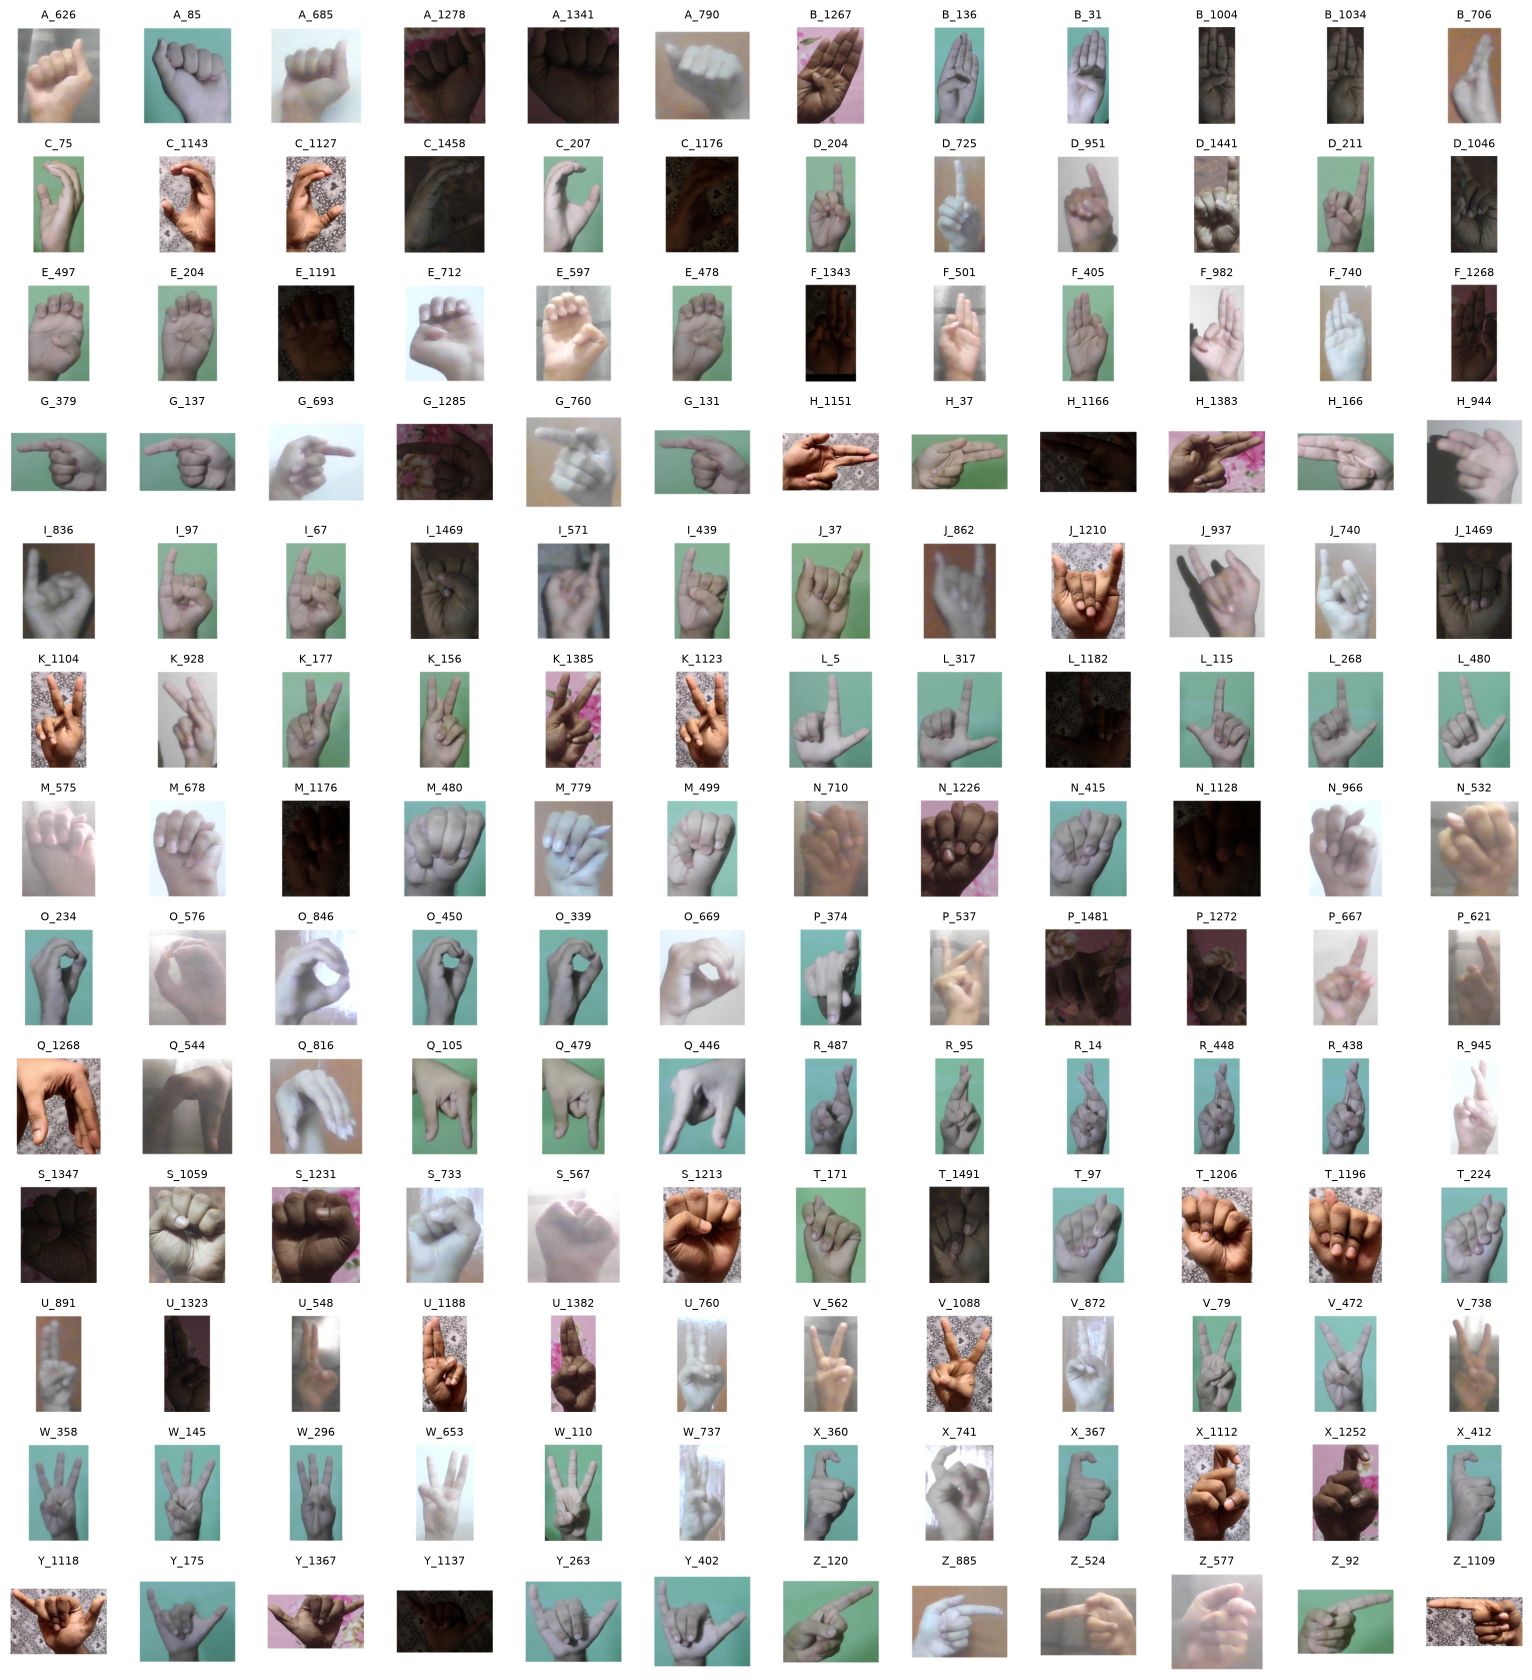

In [4]:
def show_grid(paths, titles, ncols, size=1.6, suptitle=None):
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, p, t in zip(np.ravel(axes), paths, titles):
        ax.imshow(cv2.cvtColor(common.load_image(common.DATA_DIR / p), cv2.COLOR_BGR2RGB))
        ax.set_title(t, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

per_letter = 6
picks = df[df.label.isin(common.CLASSES)].groupby("label").sample(per_letter, random_state=common.SEED)
show_grid(picks.path.tolist(), [f"{l}_{i}" for l, i in zip(picks.label, picks.idx)],
          ncols=per_letter * 2, size=1.3)

### 3. J and Z vs. the letters they should be confused with (I and D)
The proposal expects J↔I and Z↔D confusion. Check that J and Z here are the *held end pose*.

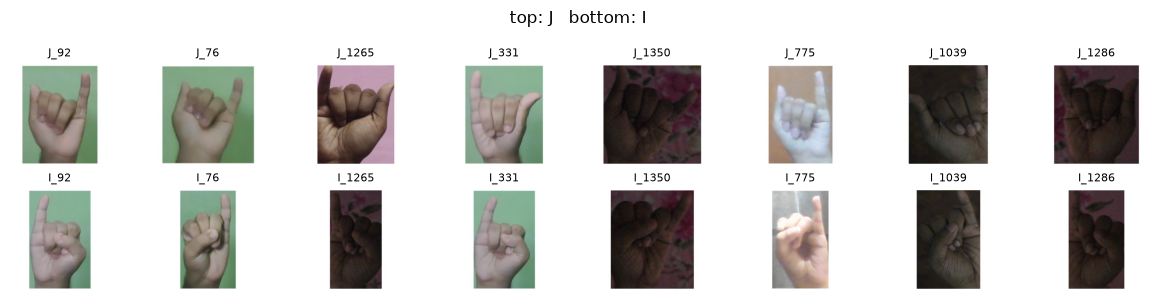

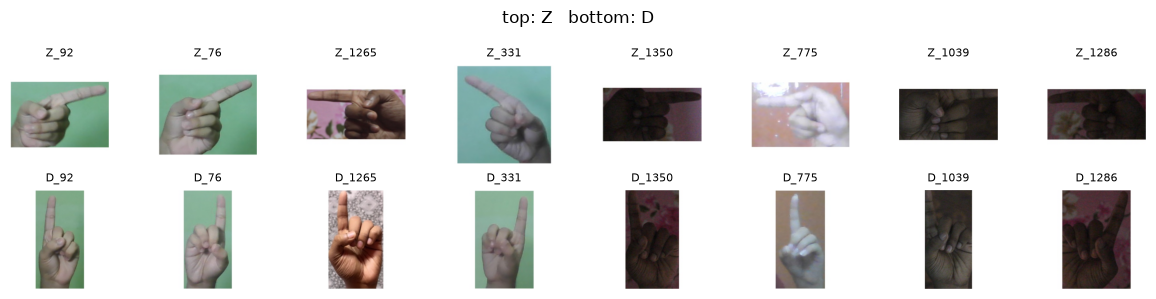

In [5]:
for a, b in [("J", "I"), ("Z", "D")]:
    g = pd.concat([df[df.label == a].sample(8, random_state=1), df[df.label == b].sample(8, random_state=1)])
    show_grid(g.path.tolist(), [f"{l}_{i}" for l, i in zip(g.label, g.idx)], ncols=8, size=1.5,
              suptitle=f"top: {a}   bottom: {b}")

### 4. Are neighbouring file numbers near-duplicates?
Filenames have **no signer/session ID**, so we can't group by person. If `A_1, A_2, A_3...` are
consecutive video frames or augmented copies of each other, a random split would put almost
identical images in both train and test and **inflate our accuracy**. This check decides the split strategy for Phase 2.

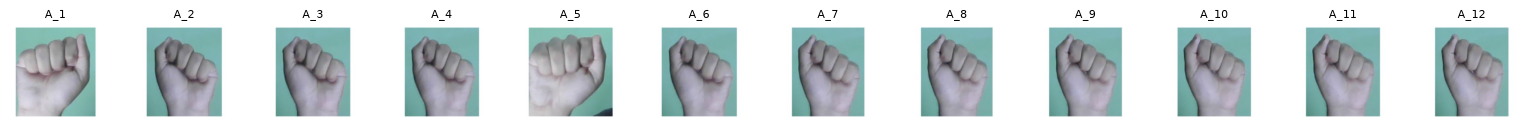

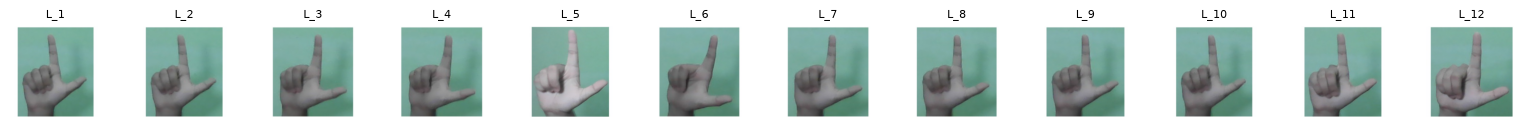

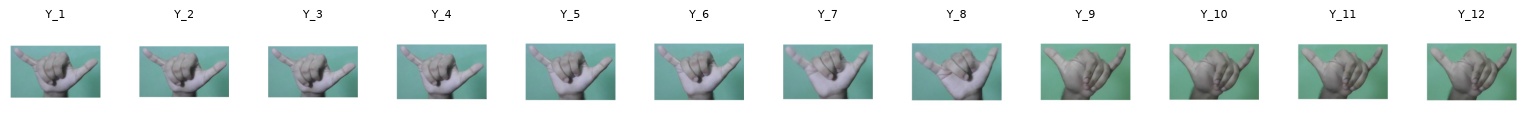

In [6]:
for letter in ["A", "L", "Y"]:
    g = df[(df.label == letter) & (df.idx <= 12)]
    show_grid(g.path.tolist(), [f"{letter}_{i}" for i in g.idx], ncols=12, size=1.3)

In [7]:
# Quantify it: pixel distance between image i and i+1 vs. two random images of the same letter.
def tiny(p):
    g = cv2.cvtColor(common.load_image(common.DATA_DIR / p), cv2.COLOR_BGR2GRAY)
    return cv2.resize(g, (16, 16), interpolation=cv2.INTER_AREA).astype(np.float32).ravel() / 255

rng = np.random.default_rng(common.SEED)
results = []
for letter in ["A", "L", "Y", "J"]:
    g = df[df.label == letter].sort_values("idx")
    X = np.stack([tiny(p) for p in g.path])
    neighbour = np.linalg.norm(X[1:] - X[:-1], axis=1)
    i, j = rng.integers(0, len(X), (2, 2000))
    random_pair = np.linalg.norm(X[i] - X[j], axis=1)
    # mirror check: is the image closest to i+1 actually the flipped version of i?
    Xf = np.stack([x.reshape(16, 16)[:, ::-1].ravel() for x in X])
    flipped_neighbour = np.linalg.norm(X[1:] - Xf[:-1], axis=1)
    results.append({"letter": letter,
                    "neighbour (i, i+1)": neighbour.mean(),
                    "neighbour vs flipped": flipped_neighbour.mean(),
                    "random pair": random_pair.mean()})
pd.DataFrame(results).round(3)

,letter,"neighbour (i, i+1)",neighbour vs flipped,random pair
0,A,1.147,2.281,4.422
1,L,1.126,2.151,4.424
2,Y,1.301,2.190,4.588
3,J,1.120,2.055,4.035


**How to read this:** if the *neighbour* distance is much smaller than the *random pair* distance,
consecutive numbers come from the same recording and must be kept **together** in one split
(split by blocks of file numbers instead of random images).

### 5. Image quality: brightness and blur per letter

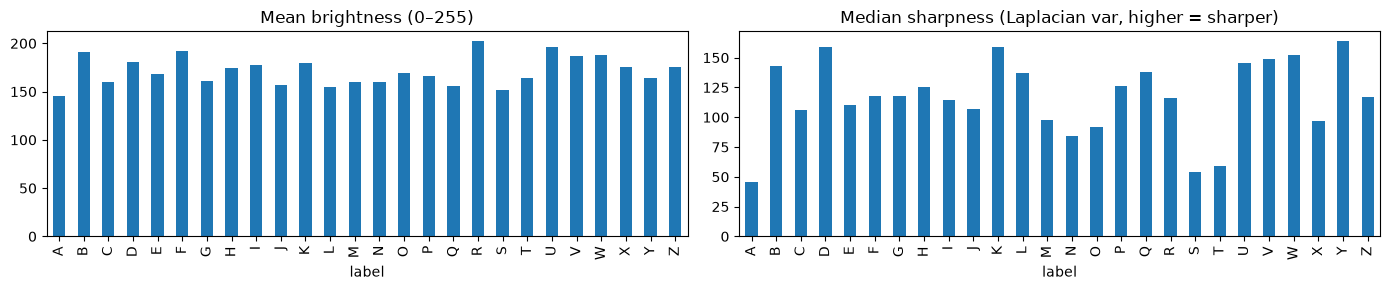

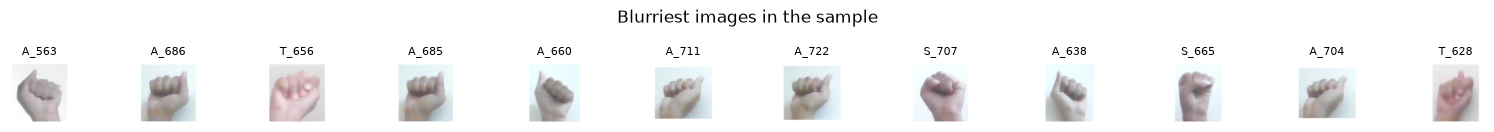

In [8]:
q = df[df.label.isin(common.CLASSES)].groupby("label").sample(100, random_state=common.SEED).copy()
def quality(p):
    g = cv2.cvtColor(common.load_image(common.DATA_DIR / p), cv2.COLOR_BGR2GRAY)
    return g.mean(), cv2.Laplacian(g, cv2.CV_64F).var()
q[["brightness", "sharpness"]] = [quality(p) for p in q.path]

fig, axes = plt.subplots(1, 2, figsize=(14, 3))
q.groupby("label").brightness.mean().plot.bar(ax=axes[0], title="Mean brightness (0–255)")
q.groupby("label").sharpness.median().plot.bar(ax=axes[1], title="Median sharpness (Laplacian var, higher = sharper)")
plt.tight_layout(); plt.show()

blurry = q.nsmallest(12, "sharpness")
show_grid(blurry.path.tolist(), [f"{l}_{i}" for l, i in zip(blurry.label, blurry.idx)], ncols=12, size=1.3,
          suptitle="Blurriest images in the sample")

### 6. Does preprocessing look right? (what each model actually sees)

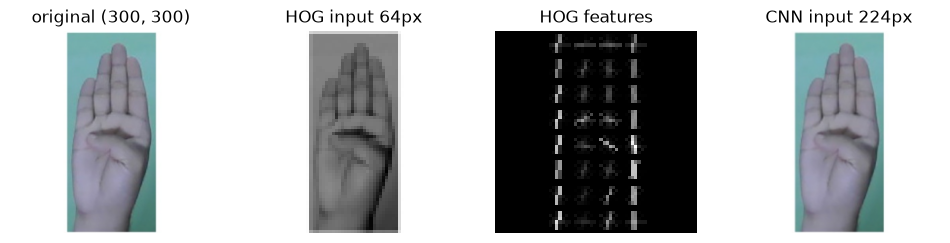

HOG feature length: 1764
CNN tensor shape: (3, 224, 224)


In [9]:
p = common.DATA_DIR / df[df.label == "B"].path.iloc[0]
img = common.load_image(p)
from skimage.feature import hog
_, hog_img = hog(common.preprocess_hog(img), visualize=True, **common.HOG_PARAMS)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title(f"original {img.shape[:2]}")
axes[1].imshow(common.preprocess_hog(img), cmap="gray"); axes[1].set_title(f"HOG input {common.HOG_IMG_SIZE}px")
axes[2].imshow(hog_img, cmap="gray"); axes[2].set_title("HOG features")
axes[3].imshow(common.prepare_rgb(img)); axes[3].set_title(f"CNN input {common.CNN_IMG_SIZE}px")
for ax in axes: ax.axis("off")
plt.show()
print("HOG feature length:", common.hog_features(img).shape[0])
print("CNN tensor shape:", common.preprocess_cnn(img).shape)

### Findings (Phase 1, run on 2026-11-21)
- **Size:** `Type_01` has 28 folders × 1500 = 42,000 photos. After dropping DEL/SPACE, **39,000** remain (1500 per letter). All are 300×300 RGB JPG.
  The proposal's "210,000 images" counts the 4 skeleton versions of the same photos, so we should correct this in the midterm report.
- **Conditions are already varied:** green screen, white walls, cluttered floral backgrounds, very dark/dim shots, and several skin tones. This is good for the webcam test.
- **White padding:** images are the hand crop pasted onto a white square (white bars on the left/right, about 30–110 px). Our webcam crop won't have these bars,
  so we need to decide how to handle them before training (trim them, or pad webcam crops the same way).
- **J / Z:** J is the held end pose (pinky up, hand turned), and it looks very similar to I. Z looks like a sideways pointing index finger, close to D/G. This matches our confusion predictions.
- **Neighbouring file numbers are near-duplicates** (consecutive video frames): the i→i+1 distance is about 1.1 vs. 4.4 for random pairs. **A random split would leak almost identical frames into the test set.**
- **Recording blocks:** big scene changes happen around file numbers **500 and 1000**, so the data appears to come from 3 blocks (1–500, 501–1000, 1001–1500).
  Matching numbers across letters look like the same session (e.g. `J_92` and `I_92` share a background).
- **Quality:** some letters are much blurrier (A, S, T lowest sharpness), and some images are very dark.

**Decisions for Phase 2:**
1. Split by **contiguous blocks of file numbers** (e.g. blocks of 50), using the *same* blocks for every letter, never by random images.
2. Draw the 500-per-letter subset from **all three recording blocks**, not just the first 500 files (those would all be one setting).
3. Group decision needed on the white padding (see above).


---
## Phase 2 · Subset and splits
**Why not a random split?** Phase 1 showed that neighbouring file numbers are near-duplicate video frames,
and frames stay more similar than random pairs even 50–100 numbers apart (each recording session lasts hundreds of frames).

**Rule we use** (the same file numbers for every letter, because matching numbers are the same session):
- The data has 3 recording blocks (`1–500`, `501–1000`, `1001–1500`). Each block is cut into **contiguous segments**:
  340 train · 70 val · 70 test, with a **10-frame gap** between segments that is thrown away.
- The segment order differs in the middle block, so the test set isn't always "end of recording".
- Keep **every 3rd frame**, giving **486 images per letter** (342 train / 72 val / 72 test), close to the proposal's "up to 500".

Every split contains all three recording blocks (all backgrounds and lighting), but no test frame is near a training frame.

In [10]:
BLOCK_LEN = 500                                   # 3 recording blocks of 500 file numbers
SEGMENTS = {"train": 340, "val": 70, "test": 70}  # + 2 gaps of 10 = 500
GAP = 10                                          # frames dropped between segments
FRAME_STEP = 3                                    # keep every 3rd frame
ORDER = {0: ["train", "val", "test"],             # segment order inside each block
         1: ["test", "val", "train"],
         2: ["train", "val", "test"]}
assert sum(SEGMENTS.values()) + GAP * (len(SEGMENTS) - 1) == BLOCK_LEN

def assign_split(idx):
    """File number (1..1500) -> (split or None if in a gap, block, position inside the segment)."""
    block, pos = (idx - 1) // BLOCK_LEN, (idx - 1) % BLOCK_LEN
    start = 0
    for name in ORDER[block]:
        end = start + SEGMENTS[name]
        if start <= pos < end:
            return name, block, pos - start
        start = end + GAP
    return None, block, None

letters = df[df.label.isin(common.CLASSES)].copy()
letters[["split", "block", "seg_pos"]] = [assign_split(i) for i in letters.idx]
subset = letters[letters.split.notna() & (letters.seg_pos % FRAME_STEP == 0)].copy()
subset["block"] = subset.block.astype(int)

counts = pd.crosstab(subset.label, subset.split)[["train", "val", "test"]]
print("Images per letter:", counts.sum(axis=1).unique(), "| total:", len(subset))
print((counts.sum() / len(subset)).round(3).to_dict())
counts.T

Images per letter: [486] | total: 12636
{'train': 0.704, 'val': 0.148, 'test': 0.148}


label,A,B,C,D,E,F,G,H,I,J,...,Q,R,S,T,U,V,W,X,Y,Z
split,,,,,,,,,,,,,,,,,,,,,
train,342,342,342,342,342,342,342,342,342,342,...,342,342,342,342,342,342,342,342,342,342
val,72,72,72,72,72,72,72,72,72,72,...,72,72,72,72,72,72,72,72,72,72
test,72,72,72,72,72,72,72,72,72,72,...,72,72,72,72,72,72,72,72,72,72


In [11]:
# Save the splits: these CSVs are the single source of truth for BOTH models.
common.SPLITS_DIR.mkdir(parents=True, exist_ok=True)
for name in ["train", "val", "test"]:
    out = subset[subset.split == name].sort_values(["label", "idx"])[["path", "label", "block", "idx"]]
    out.to_csv(common.SPLITS_DIR / f"{name}.csv", index=False)
    print(f"{name:5s} -> {common.SPLITS_DIR / (name + '.csv')}  ({len(out)} rows)")

train -> /home/roneet/Desktop/IMG467-project/data/splits/train.csv  (8892 rows)
val   -> /home/roneet/Desktop/IMG467-project/data/splits/val.csv  (1872 rows)
test  -> /home/roneet/Desktop/IMG467-project/data/splits/test.csv  (1872 rows)


### Sanity checks *(Roneet)*
1. Every letter has the same number of images in each split.
2. No image appears in two splits.
3. Train and test frames of the same letter are always more than `GAP` file numbers apart.
4. **Leakage test:** for each test image, how close is the most similar training image? We compare our block split
   with what a random split of the *same* images would give. If our split works, test images should be further from training.

In [12]:
tr, va, te = (common.load_split(n) for n in ["train", "val", "test"])

# 1. balance
for name, s in [("train", tr), ("val", va), ("test", te)]:
    assert s.label.value_counts().nunique() == 1, f"{name} is unbalanced"
    assert set(s.label) == set(common.CLASSES), f"{name} is missing letters"
# 2. no overlap
assert not (set(tr.path) & set(va.path) or set(tr.path) & set(te.path) or set(va.path) & set(te.path))
# 3. distance in file numbers
def min_gap(a, b):
    a, b = np.sort(a.idx.unique()), np.sort(b.idx.unique())
    pos = np.clip(np.searchsorted(a, b), 1, len(a) - 1)
    return int(np.minimum(np.abs(a[pos] - b), np.abs(a[pos - 1] - b)).min())
print("closest train<->test file numbers:", min_gap(tr, te), "| train<->val:", min_gap(tr, va), "| val<->test:", min_gap(va, te))
assert min(min_gap(tr, te), min_gap(tr, va), min_gap(va, te)) > GAP
print("Checks 1–3 passed: balanced, no overlap, splits separated by >", GAP, "frames")

closest train<->test file numbers: 91 | train<->val: 11 | val<->test: 11
Checks 1–3 passed: balanced, no overlap, splits separated by > 10 frames


In [13]:
# 4. leakage test: nearest training image for every test image (16x16 grayscale pixels)
rng = np.random.default_rng(common.SEED)
rows = []
for letter in ["A", "E", "J", "M", "S", "Z"]:
    s = subset[subset.label == letter]
    X = np.stack([tiny(p) for p in s.path])
    def nn_dist(train_mask, test_mask):
        A, B = X[train_mask], X[test_mask]
        d = np.sqrt(((B[:, None, :] - A[None, :, :]) ** 2).sum(-1))
        return np.median(d.min(1))
    ours = nn_dist((s.split == "train").values, (s.split == "test").values)
    rand_split = rng.permutation(s.split.values)
    rnd = nn_dist(rand_split == "train", rand_split == "test")
    rows.append({"letter": letter, "random split": rnd, "our block split": ours})
leak = pd.DataFrame(rows).set_index("letter").round(2)
leak.loc["mean"] = leak.mean().round(2)
leak

,random split,our block split
letter,,
A,0.41,1.52
E,0.46,1.38
J,0.58,1.17
M,0.41,1.19
S,0.53,1.08
Z,0.54,0.99
mean,0.49,1.22


**How to read this:** the numbers are the median distance from a test image to its closest training image.
With a random split it's tiny, because almost every test frame has a near-copy in training. That would give
inflated accuracy. Our block split pushes this up, so the test score measures generalisation, not memorisation.
*(Worth reporting in the midterm "Datasets" section.)*

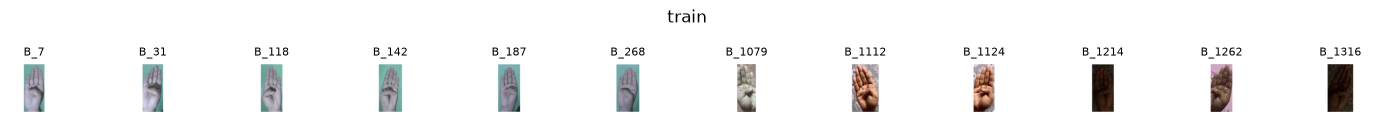

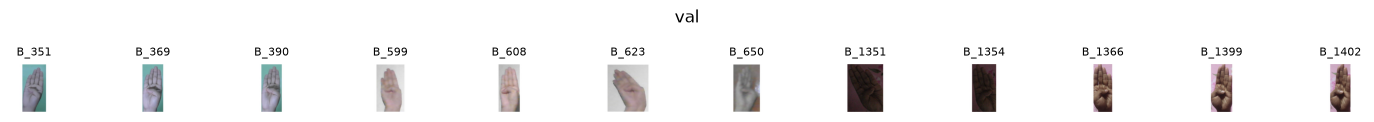

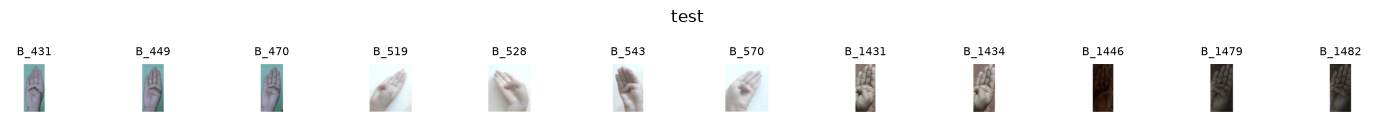

In [14]:
# What each split looks like for one letter
for name in ["train", "val", "test"]:
    g = subset[(subset.label == "B") & (subset.split == name)].sample(12, random_state=common.SEED).sort_values("idx")
    show_grid(g.path.tolist(), [f"B_{i}" for i in g.idx], ncols=12, size=1.2, suptitle=f"{name}")